# Restricted Hartree–Fock for HeH⁺ (STO-3G)

Self-consistent field (SCF) solution of the Roothaan–Hall equations **F C = S C ε** for the HeH⁺ molecular ion, written from scratch with NumPy.

* Basis: STO-3G (minimal basis, K = 2: He 1s and H 1s)
* Electrons: N = 2, closed-shell singlet
* Internuclear distance: R = 0.7743 Å = 1.4632 bohr

All one- and two-electron integrals are given as input (atomic units).

In [1]:
import numpy as np
np.set_printoptions(precision=6, suppress=True)

## 1. Integrals

Core Hamiltonian **H<sub>core</sub> = T + V**, overlap matrix **S** and the two-electron repulsion integrals (μν|λσ) in chemist notation. Only six integrals are unique; the 8-fold permutational symmetry fills the rest of the tensor.

In [2]:
# Core Hamiltonian H_core = T + V
H_core = np.array([[-2.5983, -1.4318],
                   [-1.4318, -1.7318]])

# Overlap matrix: the atomic orbitals are not orthogonal, so S is not diagonal
S = np.array([[1.0000, 0.5368],
              [0.5368, 1.0000]])

# Two-electron repulsion integrals (mu nu | lambda sigma)
eri = np.zeros((2, 2, 2, 2))

def set_eri(i, j, k, l, value):
    """Store an integral together with its 8-fold permutational symmetry."""
    for a, b, c, d in [(i, j, k, l), (j, i, k, l), (i, j, l, k), (j, i, l, k),
                       (k, l, i, j), (k, l, j, i), (l, k, i, j), (l, k, j, i)]:
        eri[a, b, c, d] = value

set_eri(0, 0, 0, 0, 1.0557)
set_eri(1, 1, 0, 0, 0.5908)
set_eri(1, 0, 0, 0, 0.4440)
set_eri(1, 1, 1, 0, 0.3674)
set_eri(1, 0, 1, 0, 0.2243)
set_eri(1, 1, 1, 1, 0.7746)

## 2. Orthogonalisation

The Roothaan equations are a generalised eigenvalue problem. With the canonical orthogonalisation matrix **X = U s<sup>−1/2</sup>** (U, s: eigenvectors and eigenvalues of S) we have **X<sup>T</sup> S X = 1**, which turns them into an ordinary eigenvalue problem **F′ C′ = C′ ε** with **F′ = X<sup>T</sup> F X** and **C = X C′**.

In [3]:
s_eigenvalues, U = np.linalg.eigh(S)
X = U @ np.diag(1.0 / np.sqrt(s_eigenvalues))

print("X =\n", X)
print("Check X^T S X =\n", X.T @ S @ X)

X =
 [[-1.038965  0.570396]
 [ 1.038965  0.570396]]
Check X^T S X =
 [[ 1. -0.]
 [ 0.  1.]]


## 3. SCF loop

The Fock matrix depends on the density matrix **P**, which in turn depends on the orbitals we want to compute. We therefore start from a guess, **P = 0**: the electrons only feel the fixed nuclei (core Hamiltonian guess). Each iteration then:

1. builds **G<sub>μν</sub> = Σ<sub>λσ</sub> P<sub>λσ</sub> [(μν|σλ) − ½ (μλ|σν)]** and **F = H<sub>core</sub> + G**
2. solves **F′ C′ = C′ ε** and back-transforms **C = X C′**
3. forms the new density **P<sub>μν</sub> = 2 C<sub>μ1</sub> C<sub>ν1</sub>** (one doubly occupied orbital)
4. evaluates **E<sub>elec</sub> = ½ Σ<sub>μν</sub> P<sub>μν</sub> (H<sub>core</sub> + F)<sub>μν</sub>**

until both the density and the energy stop changing.

In [4]:
P = np.zeros((2, 2))          # core-Hamiltonian guess
tolerance_P = 1e-8
tolerance_E = 1e-6
max_iter = 50

E_old = 0.0
history = []

for iteration in range(1, max_iter + 1):
    # Two-electron part of the Fock matrix
    G = np.zeros((2, 2))
    for mu in range(2):
        for nu in range(2):
            for lam in range(2):
                for sig in range(2):
                    J = eri[mu, nu, sig, lam]     # Coulomb
                    K = eri[mu, lam, sig, nu]     # exchange
                    G[mu, nu] += P[lam, sig] * (J - 0.5 * K)

    F = H_core + G

    # Solve in the orthogonal basis and transform back
    F_prime = X.T @ F @ X
    eps, C_prime = np.linalg.eigh(F_prime)
    C = X @ C_prime

    # New density matrix: 2 electrons in the lowest orbital
    P_new = 2.0 * np.outer(C[:, 0], C[:, 0])

    # Electronic energy
    E_elec = 0.5 * np.sum(P_new * (H_core + F))

    # Convergence check
    delta_P = np.sum((P_new - P) ** 2)
    delta_E = abs(E_elec - E_old)
    history.append((iteration, E_elec, delta_P, delta_E))
    print(f"iter {iteration:2d}   E_elec = {E_elec:.8f}   dP = {delta_P:.2e}   dE = {delta_E:.2e}")

    P, E_old = P_new, E_elec
    if delta_P < tolerance_P and delta_E < tolerance_E:
        print(f"\nSCF converged in {iteration} iterations")
        break

iter  1   E_elec = -5.19962294   dP = 3.66e+00   dE = 5.20e+00
iter  2   E_elec = -4.16613352   dP = 2.04e-01   dE = 1.03e+00
iter  3   E_elec = -4.20140880   dP = 6.43e-03   dE = 3.53e-02
iter  4   E_elec = -4.20757715   dP = 1.60e-04   dE = 6.17e-03
iter  5   E_elec = -4.20854533   dP = 3.81e-06   dE = 9.68e-04
iter  6   E_elec = -4.20869451   dP = 8.99e-08   dE = 1.49e-04
iter  7   E_elec = -4.20871743   dP = 2.12e-09   dE = 2.29e-05
iter  8   E_elec = -4.20872095   dP = 5.00e-11   dE = 3.52e-06
iter  9   E_elec = -4.20872149   dP = 1.18e-12   dE = 5.40e-07

SCF converged in 9 iterations


## 4. Results

In [5]:
R_bohr = 0.7743 * 1.889725989        # 0.7743 Angstrom in bohr
Z_He, Z_H = 2.0, 1.0
E_nuc = Z_He * Z_H / R_bohr
E_SCF = E_elec + E_nuc

print("Density matrix P =\n", P)
print("Fock matrix F =\n", F)
print("MO coefficients C (columns) =\n", C)
print(f"\nOrbital energies: occupied {eps[0]:.6f}, virtual {eps[1]:.6f} Hartree")
print(f"Electronic energy      E_elec = {E_elec:.8f} Hartree")
print(f"Nuclear repulsion      E_nuc  = {E_nuc:.8f} Hartree")
print(f"Total SCF energy       E_SCF  = {E_SCF:.8f} Hartree")

Density matrix P =
 [[1.536942 0.354956]
 [0.354956 0.081977]]
Fock matrix F =
 [[-1.590186 -1.060969]
 [-1.060969 -0.833982]]
MO coefficients C (columns) =
 [[ 0.876625  0.797702]
 [ 0.202456 -1.167823]]

Orbital energies: occupied -1.632793, virtual -0.172531 Hartree
Electronic energy      E_elec = -4.20872149 Hartree
Nuclear repulsion      E_nuc  = 1.36685328 Hartree
Total SCF energy       E_SCF  = -2.84186821 Hartree


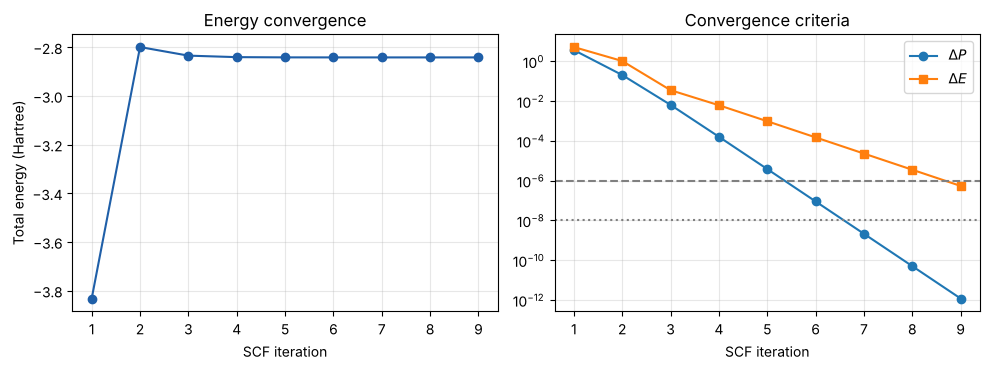

In [6]:
import matplotlib.pyplot as plt

it, E_hist, dP_hist, dE_hist = np.array(history).T
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(it, E_hist + E_nuc, "o-", color="#1f5fa8")
ax[0].set_xlabel("SCF iteration"); ax[0].set_ylabel("Total energy (Hartree)")
ax[0].set_title("Energy convergence")
ax[1].semilogy(it, dP_hist, "o-", label=r"$\Delta P$")
ax[1].semilogy(it, dE_hist, "s-", label=r"$\Delta E$")
ax[1].axhline(tolerance_P, ls=":", c="gray"); ax[1].axhline(tolerance_E, ls="--", c="gray")
ax[1].set_xlabel("SCF iteration"); ax[1].set_title("Convergence criteria"); ax[1].legend()
for a in ax: a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("scf_convergence.png", dpi=150)
plt.show()